In [1]:
# Parameters — modify these to analyze a different model/session
MODEL_ID      = "lgbm_solusdt_l_fw60_2101_2605"
DIRECTION     = "long"   # "long" or "short"
STRATEGY_DIR  = ""       # default: auto-derived from MODEL_ID
VALID_START   = ""       # default: from strategy_artifact fit_period.start
VALID_END     = ""       # default: from strategy_artifact fit_period.end


In [2]:
# Parameters
MODEL_ID = "lgbm_solusdt_s_fw60_2101_2607"
DIRECTION = "short"
STRATEGY_DIR = "D:\\repos\\chronoquant\\artifacts\\lgbm_solusdt_s_fw60_2101_2607\\strategy"
VALID_START = "2026-02-01"
VALID_END = "2026-07-31"


## How the Strategy Works

The strategy converts the model's raw prediction score into a trading decision using three offline-derived components:

1. **Rank calibration** -- the raw `short_pred` score is mapped to a rank percentile `short_pct` (0-1) using a lookup table built on the calibration period (`rank_lookup_short.parquet`). **Low `short_pct`** (near 0) means the current bar is in the top percentile of short signals — the most negative short_mfe predictions. See: `_doc_/methodology_doc/6100_strategy_calibration.md`

2. **Entry rule** -- a bar triggers a short entry when `(1 - short_pct) >= 0.94`, i.e. `short_pct <= 0.06` (bottom 6% of the calibration distribution = most extreme short signals). Entry is at the close price of the trigger bar. See: `_doc_/methodology_doc/6300_strategy_grid_search.md`

3. **Exit rule** -- two possible exits, whichever comes first:
   - **Take Profit**: when the next bar's **low** reaches `entry_close x exp(bucket_median_mfe)`, i.e. approximately -1.16% log return below entry (price drops to TP)
   - **Timeout**: if TP is not reached within 60 bars (60 minutes), the position closes at the 60th bar's close
   - No stop loss is set (`sl_spec: none`)

The TP level (`bucket_median_mfe = -0.011611`) is the median realized MFE across all top-bucket calibration samples. Short: profit when price falls.

See overall strategy design: `_doc_/methodology_doc/6000_strategy.md`

In [3]:
import sys
import json
import base64
import io
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from IPython.display import display, HTML

from analyst.lib.db_utils import find_repo_root, db_path as _live_db_path, lab_db_path as _lab_db_path
from analyst.lib.plot_utils import CQ_COLORS, CQ_SEQUENCE, setup_cq_theme
setup_cq_theme()

REPO    = find_repo_root()
LIVE_DB = _live_db_path()
LAB_DB  = _lab_db_path()

_strategy_dir = Path(STRATEGY_DIR) if STRATEGY_DIR else REPO / 'artifacts' / MODEL_ID / 'strategy'
_artifact     = json.loads((_strategy_dir / 'strategy_artifact.json').read_text(encoding='utf-8'))
ENTRY_CUTOFF  = float(_artifact['decision_params']['entry_cutoff'])
SESSION_ID    = _artifact.get('session_id', '')

if not VALID_START:
    VALID_START = _artifact.get('fit_period', {}).get('start', '')
if not VALID_END:
    VALID_END = _artifact.get('fit_period', {}).get('end', '')

_lookup_file = f'rank_lookup_{DIRECTION}.parquet'
rl           = pd.read_parquet(_strategy_dir / _lookup_file)
_pred_col    = f'{DIRECTION}_pred'
_pct_col     = f'{DIRECTION}_pct'

if DIRECTION == 'long':
    _top_bucket = rl[rl['score_pct'] >= ENTRY_CUTOFF]
    TP_LOG      = float(_top_bucket['bucket_median_mfe'].iloc[0])
else:
    _top_bucket = rl[rl['score_pct'] <= (1.0 - ENTRY_CUTOFF)]
    TP_LOG      = float(_top_bucket['bucket_median_mfe'].iloc[-1])
MAX_HOLD = int(_artifact['decision_params']['max_hold_minutes'])

DOT_GREEN  = '#0ecb81'
DOT_YELLOW = '#f0b90b'
DOT_RED    = '#f6465d'

# Actual trades from strat table
_con_lab  = duckdb.connect(LAB_DB, read_only=True)
trades_df = _con_lab.execute(f'''
    SELECT entry_time, exit_time, entry_price, exit_price,
           fact_log_return, exit_reason, hold_minutes
    FROM strat."{SESSION_ID}__trades"
    WHERE entry_time >= '{VALID_START}'
    ORDER BY entry_time
''').fetchdf()
_con_lab.close()

trades_df['entry_time'] = pd.to_datetime(trades_df['entry_time'])
trades_df['exit_time']  = pd.to_datetime(trades_df['exit_time'])
trades_df['outcome']    = trades_df.apply(
    lambda r: 'green' if r['exit_reason'] == 'tp'
    else ('yellow' if r['fact_log_return'] > 0 else 'red'),
    axis=1,
)
trades_df['color'] = trades_df['outcome'].map(
    {'green': DOT_GREEN, 'yellow': DOT_YELLOW, 'red': DOT_RED}
)
outcome_lookup = {pd.Timestamp(r['entry_time']): r['color'] for _, r in trades_df.iterrows()}

_valid_start_dt = pd.Timestamp(VALID_START)
_chart_end      = (_valid_start_dt + pd.Timedelta(days=7)).strftime('%Y-%m-%d')

con = duckdb.connect(LIVE_DB, read_only=True)
df  = con.execute(f"""
    SELECT p.open_time, p.long_pred, p.short_pred, o.high, o.low, o.close
    FROM predictions p
    JOIN ohlcv o ON p.open_time = o.open_time
    WHERE p.open_time >= '{VALID_START}' AND p.open_time < '{_chart_end}'
    ORDER BY p.open_time
""").fetchdf()
con.close()

df['open_time'] = pd.to_datetime(df['open_time'])
df[_pct_col]    = np.interp(
    df[_pred_col].to_numpy(),
    rl['score_raw'].to_numpy(),
    rl['score_pct'].to_numpy(),
).clip(0, 1)

_entry_label = (
    f'{ENTRY_CUTOFF}'
    if DIRECTION == 'long'
    else f'{ENTRY_CUTOFF}  (short: score_pct <= {1.0 - ENTRY_CUTOFF:.2f})'
)
display(pd.DataFrame([
    {'Key': 'Rows loaded',               'Value': f'{len(df):,}'},
    {'Key': 'Date range',                'Value': f"{df['open_time'].min().date()} - {df['open_time'].max().date()}"},
    {'Key': 'Entry cutoff',              'Value': _entry_label},
    {'Key': 'TP log return',             'Value': f'{TP_LOG:.6f}  ({TP_LOG*100:.4f}%)'},
    {'Key': 'Max hold (min)',            'Value': f'{MAX_HOLD}'},
    {'Key': 'Total trades (validation)', 'Value': f'{len(trades_df)}'},
]).set_index('Key'))


,Value
Key,
Rows loaded,"10,080"
Date range,2026-02-01 - 2026-02-07
Entry cutoff,0.92 (short: score_pct <= 0.08)
TP log return,-0.006620 (-0.6620%)
Max hold (min),60
Total trades (validation),2988


## Strategy Summary

In [4]:
rows = [
    {"Parameter": "Model",             "Value": _artifact[f"{DIRECTION}_model"]},
    {"Parameter": "Direction",         "Value": DIRECTION},
    {"Parameter": "Entry cutoff",      "Value": ENTRY_CUTOFF},
    {"Parameter": "TP spec",           "Value": _artifact["decision_params"]["tp_spec"]},
    {"Parameter": "SL spec",           "Value": _artifact["decision_params"]["sl_spec"]},
    {"Parameter": "Max hold (min)",    "Value": _artifact["decision_params"]["max_hold_minutes"]},
    {"Parameter": "Signal mode",       "Value": _artifact["signal_mode"]},
    {"Parameter": "N trades (valid)",  "Value": _artifact["metrics"]["n_trades"]},
    {"Parameter": "Win rate",          "Value": f"{_artifact['metrics']['win_rate']:.1%}"},
    {"Parameter": "Compounded return", "Value": f"{_artifact['metrics']['compounded_return_pct']:.2f}%"},
    {"Parameter": "Fit period",        "Value": f"{_artifact['fit_period']['start']} - {_artifact['fit_period']['end']}"},
    {"Parameter": "Chart period",      "Value": f"{VALID_START} - {_chart_end} (first validation week)"},
]

summary_df = pd.DataFrame(rows)
summary_df.style.set_table_attributes('class="dataframe"').hide(axis="index")


Parameter,Value
Model,lgbm_solusdt_s_fw60_2101_2607
Direction,short
Entry cutoff,0.920000
TP spec,bucket_median_mfe
SL spec,0.5x_tp
Max hold (min),60
Signal mode,rank_first
N trades (valid),2988
Win rate,34.1%
Compounded return,18.29%


## Weekly Trade Summary

In [5]:
# Full validation period data for charts
TRADE_SIZE = 1000.0

con2   = duckdb.connect(LIVE_DB, read_only=True)
df_all = con2.execute(f"""
    SELECT p.open_time, p.long_pred, p.short_pred, o.high, o.low, o.close
    FROM predictions p
    JOIN ohlcv o ON p.open_time = o.open_time
    WHERE p.open_time >= '{VALID_START}'
    ORDER BY p.open_time
""").fetchdf()
con2.close()

df_all['open_time'] = pd.to_datetime(df_all['open_time'])
df_all[_pct_col] = np.interp(
    df_all[_pred_col].to_numpy(),
    rl['score_raw'].to_numpy(),
    rl['score_pct'].to_numpy()
).clip(0, 1)

# Weekly summary from actual strat-table trades
trades_week = trades_df.copy()
trades_week['week'] = trades_week['entry_time'].dt.to_period('W').dt.start_time.dt.date
trades_week['pnl']  = TRADE_SIZE * (np.exp(trades_week['fact_log_return']) - 1)

weekly = trades_week.groupby('week').apply(lambda g: pd.Series({
    'Trades':  len(g),
    'Green':   (g['outcome'] == 'green').sum(),
    'Yellow':  (g['outcome'] == 'yellow').sum(),
    'Red':     (g['outcome'] == 'red').sum(),
    'G_gain':  g.loc[g['outcome'] == 'green',  'pnl'].sum(),
    'Y_gain':  g.loc[g['outcome'] == 'yellow', 'pnl'].sum(),
    'R_gain':  g.loc[g['outcome'] == 'red',    'pnl'].sum(),
}), include_groups=False).reset_index()

weekly['TP Rate'] = (weekly['Green'] / weekly['Trades'] * 100).round(1).astype(str) + '%'
weekly['Net ($)'] = weekly['G_gain'] + weekly['Y_gain'] + weekly['R_gain']

totals = {
    'week': 'TOTAL',
    'Trades':  int(weekly['Trades'].sum()),
    'Green':   int(weekly['Green'].sum()),
    'Yellow':  int(weekly['Yellow'].sum()),
    'Red':     int(weekly['Red'].sum()),
    'G_gain':  weekly['G_gain'].sum(),
    'Y_gain':  weekly['Y_gain'].sum(),
    'R_gain':  weekly['R_gain'].sum(),
    'TP Rate': f"{weekly['Green'].sum()/weekly['Trades'].sum()*100:.1f}%" if weekly['Trades'].sum() > 0 else '0%',
    'Net ($)': weekly['Net ($)'].sum(),
}

from IPython.display import Markdown


def fmt_usd(v):
    sign = '+' if v >= 0 else ''
    return f'{sign}{v:,.0f}'


header   = '| Week | Trades | Green | Yellow | Red | TP Rate | Green $ | Yellow $ | Red $ | Net $ |'
sep      = '| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |'
md_lines = [header, sep]

for _, r in weekly.iterrows():
    md_lines.append(
        f"| {r['week']} | {int(r['Trades'])} "
        f"| <span style='color:#0ecb81;font-weight:bold'>{int(r['Green'])}</span> "
        f"| <span style='color:#f0b90b;font-weight:bold'>{int(r['Yellow'])}</span> "
        f"| <span style='color:#f6465d;font-weight:bold'>{int(r['Red'])}</span> "
        f"| {r['TP Rate']} "
        f"| <span style='color:#0ecb81'>{fmt_usd(r['G_gain'])}</span> "
        f"| <span style='color:#f0b90b'>{fmt_usd(r['Y_gain'])}</span> "
        f"| <span style='color:#f6465d'>{fmt_usd(r['R_gain'])}</span> "
        f"| **{fmt_usd(r['Net ($)'])}** |"
    )

md_lines.append(
    f"| **{totals['week']}** | **{totals['Trades']}** "
    f"| **<span style='color:#0ecb81'>{totals['Green']}</span>** "
    f"| **<span style='color:#f0b90b'>{totals['Yellow']}</span>** "
    f"| **<span style='color:#f6465d'>{totals['Red']}</span>** "
    f"| **{totals['TP Rate']}** "
    f"| **<span style='color:#0ecb81'>{fmt_usd(totals['G_gain'])}</span>** "
    f"| **<span style='color:#f0b90b'>{fmt_usd(totals['Y_gain'])}</span>** "
    f"| **<span style='color:#f6465d'>{fmt_usd(totals['R_gain'])}</span>** "
    f"| **{fmt_usd(totals['Net ($)'])}** |"
)

display(Markdown(chr(10).join(md_lines)))


| Week | Trades | Green | Yellow | Red | TP Rate | Green $ | Yellow $ | Red $ | Net $ |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026-01-26 | 84 | <span style='color:#0ecb81;font-weight:bold'>33</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>51</span> | 39.3% | <span style='color:#0ecb81'>+219</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-169</span> | **+51** |
| 2026-02-02 | 817 | <span style='color:#0ecb81;font-weight:bold'>273</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>543</span> | 33.4% | <span style='color:#0ecb81'>+1,813</span> | <span style='color:#f0b90b'>+4</span> | <span style='color:#f6465d'>-1,794</span> | **+22** |
| 2026-02-09 | 182 | <span style='color:#0ecb81;font-weight:bold'>61</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>120</span> | 33.5% | <span style='color:#0ecb81'>+405</span> | <span style='color:#f0b90b'>+1</span> | <span style='color:#f6465d'>-395</span> | **+11** |
| 2026-02-16 | 103 | <span style='color:#0ecb81;font-weight:bold'>35</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>68</span> | 34.0% | <span style='color:#0ecb81'>+232</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-225</span> | **+8** |
| 2026-02-23 | 243 | <span style='color:#0ecb81;font-weight:bold'>82</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>161</span> | 33.7% | <span style='color:#0ecb81'>+545</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-529</span> | **+15** |
| 2026-03-02 | 194 | <span style='color:#0ecb81;font-weight:bold'>58</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>135</span> | 29.9% | <span style='color:#0ecb81'>+385</span> | <span style='color:#f0b90b'>+3</span> | <span style='color:#f6465d'>-446</span> | **-58** |
| 2026-03-09 | 116 | <span style='color:#0ecb81;font-weight:bold'>37</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>78</span> | 31.9% | <span style='color:#0ecb81'>+246</span> | <span style='color:#f0b90b'>+2</span> | <span style='color:#f6465d'>-258</span> | **-10** |
| 2026-03-16 | 54 | <span style='color:#0ecb81;font-weight:bold'>20</span> | <span style='color:#f0b90b;font-weight:bold'>2</span> | <span style='color:#f6465d;font-weight:bold'>32</span> | 37.0% | <span style='color:#0ecb81'>+133</span> | <span style='color:#f0b90b'>+6</span> | <span style='color:#f6465d'>-106</span> | **+33** |
| 2026-03-23 | 47 | <span style='color:#0ecb81;font-weight:bold'>11</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>36</span> | 23.4% | <span style='color:#0ecb81'>+73</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-119</span> | **-46** |
| 2026-03-30 | 61 | <span style='color:#0ecb81;font-weight:bold'>23</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>37</span> | 37.7% | <span style='color:#0ecb81'>+153</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-122</span> | **+31** |
| 2026-04-06 | 40 | <span style='color:#0ecb81;font-weight:bold'>12</span> | <span style='color:#f0b90b;font-weight:bold'>2</span> | <span style='color:#f6465d;font-weight:bold'>26</span> | 30.0% | <span style='color:#0ecb81'>+80</span> | <span style='color:#f0b90b'>+6</span> | <span style='color:#f6465d'>-86</span> | **-1** |
| 2026-04-13 | 36 | <span style='color:#0ecb81;font-weight:bold'>9</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>27</span> | 25.0% | <span style='color:#0ecb81'>+60</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-89</span> | **-29** |
| 2026-04-27 | 5 | <span style='color:#0ecb81;font-weight:bold'>1</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>4</span> | 20.0% | <span style='color:#0ecb81'>+7</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-11</span> | **-4** |
| 2026-05-04 | 11 | <span style='color:#0ecb81;font-weight:bold'>1</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>10</span> | 9.1% | <span style='color:#0ecb81'>+7</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-33</span> | **-26** |
| 2026-05-11 | 18 | <span style='color:#0ecb81;font-weight:bold'>3</span> | <span style='color:#f0b90b;font-weight:bold'>2</span> | <span style='color:#f6465d;font-weight:bold'>13</span> | 16.7% | <span style='color:#0ecb81'>+20</span> | <span style='color:#f0b90b'>+8</span> | <span style='color:#f6465d'>-43</span> | **-15** |
| 2026-05-18 | 20 | <span style='color:#0ecb81;font-weight:bold'>5</span> | <span style='color:#f0b90b;font-weight:bold'>2</span> | <span style='color:#f6465d;font-weight:bold'>13</span> | 25.0% | <span style='color:#0ecb81'>+33</span> | <span style='color:#f0b90b'>+2</span> | <span style='color:#f6465d'>-40</span> | **-4** |
| 2026-05-25 | 14 | <span style='color:#0ecb81;font-weight:bold'>4</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>10</span> | 28.6% | <span style='color:#0ecb81'>+27</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-31</span> | **-5** |
| 2026-06-01 | 489 | <span style='color:#0ecb81;font-weight:bold'>181</span> | <span style='color:#f0b90b;font-weight:bold'>3</span> | <span style='color:#f6465d;font-weight:bold'>305</span> | 37.0% | <span style='color:#0ecb81'>+1,202</span> | <span style='color:#f0b90b'>+10</span> | <span style='color:#f6465d'>-1,005</span> | **+207** |
| 2026-06-08 | 96 | <span style='color:#0ecb81;font-weight:bold'>28</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>68</span> | 29.2% | <span style='color:#0ecb81'>+186</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-225</span> | **-39** |
| 2026-06-15 | 57 | <span style='color:#0ecb81;font-weight:bold'>23</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>34</span> | 40.4% | <span style='color:#0ecb81'>+153</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-111</span> | **+42** |
| 2026-06-22 | 159 | <span style='color:#0ecb81;font-weight:bold'>62</span> | <span style='color:#f0b90b;font-weight:bold'>0</span> | <span style='color:#f6465d;font-weight:bold'>97</span> | 39.0% | <span style='color:#0ecb81'>+412</span> | <span style='color:#f0b90b'>+0</span> | <span style='color:#f6465d'>-321</span> | **+91** |
| 2026-06-29 | 103 | <span style='color:#0ecb81;font-weight:bold'>29</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>73</span> | 28.2% | <span style='color:#0ecb81'>+193</span> | <span style='color:#f0b90b'>+2</span> | <span style='color:#f6465d'>-241</span> | **-47** |
| 2026-07-06 | 27 | <span style='color:#0ecb81;font-weight:bold'>5</span> | <span style='color:#f0b90b;font-weight:bold'>2</span> | <span style='color:#f6465d;font-weight:bold'>20</span> | 18.5% | <span style='color:#0ecb81'>+33</span> | <span style='color:#f0b90b'>+3</span> | <span style='color:#f6465d'>-66</span> | **-30** |
| 2026-07-13 | 7 | <span style='color:#0ecb81;font-weight:bold'>1</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>5</span> | 14.3% | <span style='color:#0ecb81'>+7</span> | <span style='color:#f0b90b'>+1</span> | <span style='color:#f6465d'>-17</span> | **-8** |
| 2026-07-27 | 5 | <span style='color:#0ecb81;font-weight:bold'>2</span> | <span style='color:#f0b90b;font-weight:bold'>1</span> | <span style='color:#f6465d;font-weight:bold'>2</span> | 40.0% | <span style='color:#0ecb81'>+13</span> | <span style='color:#f0b90b'>+1</span> | <span style='color:#f6465d'>-4</span> | **+11** |
| **TOTAL** | **2988** | **<span style='color:#0ecb81'>999</span>** | **<span style='color:#f0b90b'>21</span>** | **<span style='color:#f6465d'>1968</span>** | **33.4%** | **<span style='color:#0ecb81'>+6,636</span>** | **<span style='color:#f0b90b'>+50</span>** | **<span style='color:#f6465d'>-6,485</span>** | **+201** |

## Validation Period - Day Charts

One section per week with at least one short trigger. Each section contains 7-day tabsets. Dot colors: green = TP hit (low touched), yellow = timeout positive (price dropped), red = timeout negative (price rose).

C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


... (165 outputs left out)

C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\eross\AppData\Local\Temp\ipykernel_9016\990296272.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



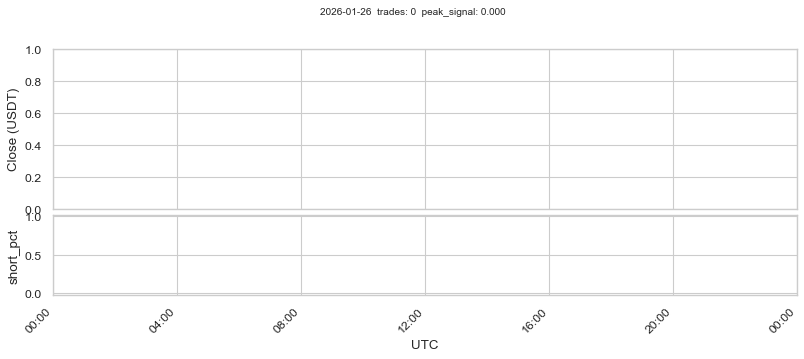
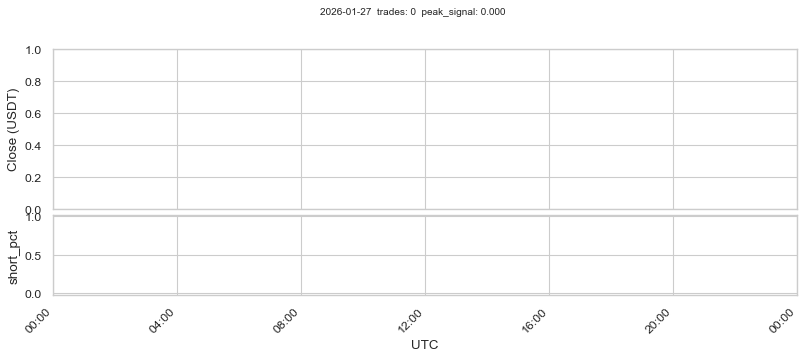
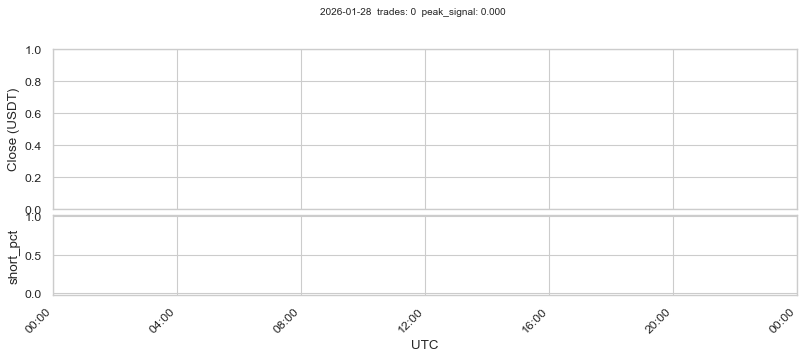
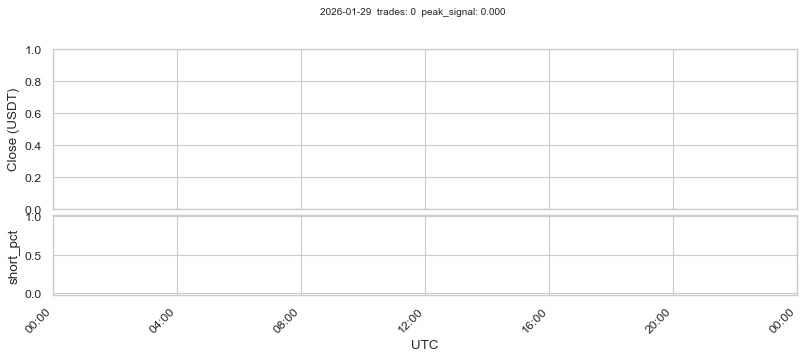
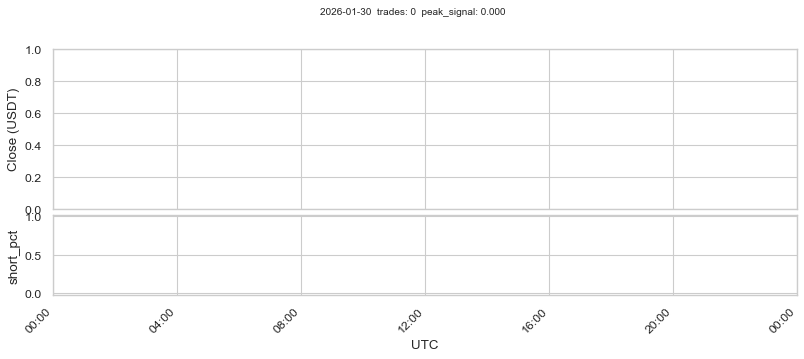
...
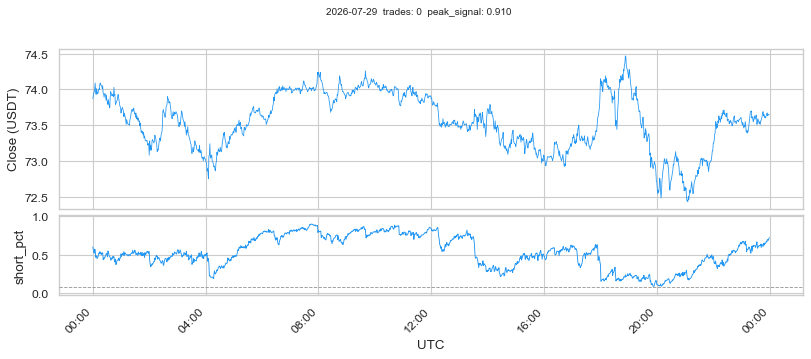
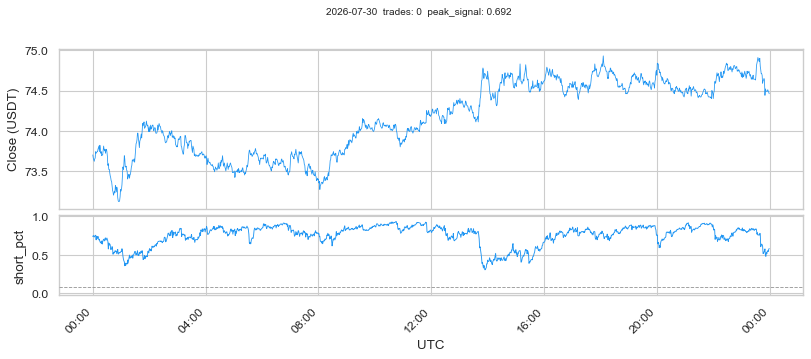
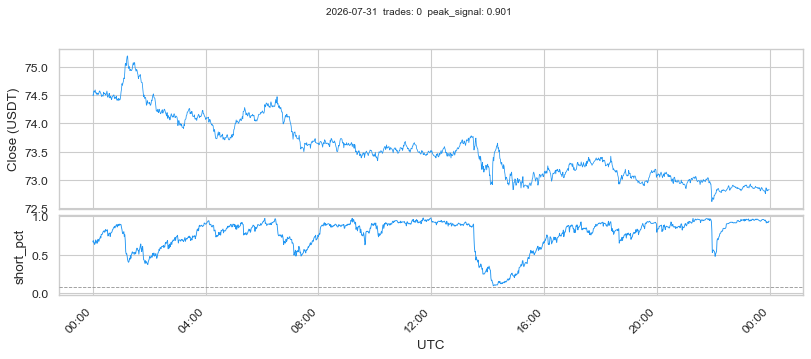
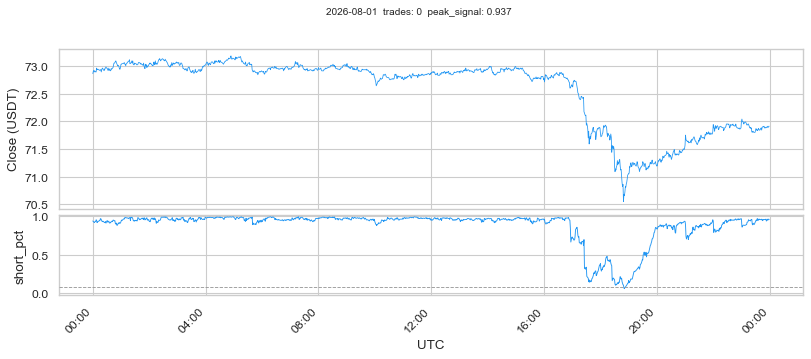
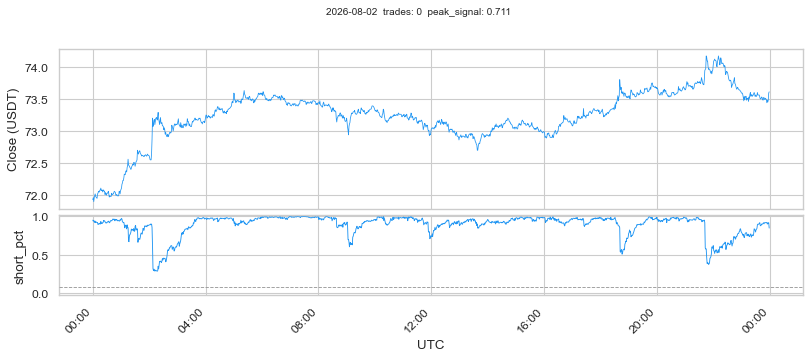

In [6]:
#| echo: false
import base64, io
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, HTML

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 80, 'font.size': 9})

# Weeks with at least 1 actual trade
trigger_weeks = sorted(trades_week['week'].unique())

accordion_items = []

for w_idx, week_date in enumerate(trigger_weeks):
    week_start    = pd.Timestamp(week_date)
    week_end      = week_start + pd.Timedelta(days=6)
    week_str      = week_start.strftime('%Y-%m-%d')
    n_trades_week = int((trades_week['week'] == week_date).sum())

    nav_items = []
    tab_panes = []
    first_tab = True

    for day_offset in range(7):
        day     = week_start + pd.Timedelta(days=day_offset)
        day_str = day.strftime('%Y-%m-%d')
        tab_id  = f'tab-{week_str}-{day_offset}'

        day_df     = df_all[df_all['open_time'].dt.date == day.date()].copy()
        trades_day = trades_df[trades_df['entry_time'].dt.date == day.date()]

        fig, (ax1, ax2) = plt.subplots(
            2, 1, sharex=True, figsize=(12, 4),
            gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.05}
        )

        if len(day_df) > 0:
            ax1.plot(day_df['open_time'], day_df['close'],
                     color='#2196F3', lw=0.7, zorder=2)
            ax2.plot(day_df['open_time'], day_df[_pct_col],
                     color='#2196F3', lw=0.8, zorder=2)
            _thr = ENTRY_CUTOFF if DIRECTION == 'long' else 1.0 - ENTRY_CUTOFF
            ax2.axhline(_thr, color='#999', lw=0.8, ls='--', zorder=3)

        for _, trow in trades_day.iterrows():
            ax1.scatter([trow['entry_time']], [trow['entry_price']],
                        color=trow['color'], marker='o', s=60, zorder=5)

        ax2.set_ylim(-0.02, 1.02)
        ax2.set_ylabel(f'{_pct_col}')
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax2.xaxis.set_major_locator(mdates.HourLocator(interval=4))
        plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')
        ax2.set_xlabel('UTC')
        ax1.set_ylabel('Close (USDT)')
        ax1.tick_params(axis='x', labelbottom=False)

        _peak = (day_df[_pct_col].max() if DIRECTION == 'long' else (1.0 - day_df[_pct_col]).max()) if len(day_df) else 0
        n_trades_day = len(trades_day)
        fig.suptitle(
            f'{day_str}  trades: {n_trades_day}  peak_signal: {_peak:.3f}',
            fontsize=9, y=1.01
        )
        plt.tight_layout()

        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=80, bbox_inches='tight')
        buf.seek(0)
        img_b64 = base64.b64encode(buf.read()).decode()
        plt.close(fig)

        active_cls = 'active' if first_tab else ''
        show_cls   = 'show active' if first_tab else ''
        nav_items.append(
            f'<li class="nav-item" role="presentation">'
            f'<button class="nav-link {active_cls}" id="{tab_id}-btn" '
            f'data-bs-toggle="tab" data-bs-target="#{tab_id}" '
            f'type="button" role="tab">{day.strftime("%a %d")}</button></li>'
        )
        tab_panes.append(
            f'<div class="tab-pane fade {show_cls}" id="{tab_id}" role="tabpanel">'
            f'<img src="data:image/png;base64,{img_b64}" '
            f'style="width:100%;max-width:1100px">'
            f'</div>'
        )
        first_tab = False

    tabset_html = (
        '<ul class="nav nav-tabs mb-2" role="tablist">' + ''.join(nav_items) + '</ul>'
        '<div class="tab-content mb-2">' + ''.join(tab_panes) + '</div>'
    )

    badge    = f'<span class="badge bg-success ms-2">{n_trades_week} trade</span>'
    is_first = (w_idx == 0)
    collapse_cls = 'show' if is_first else ''
    btn_cls      = '' if is_first else ' collapsed'

    accordion_items.append(
        f'<div class="accordion-item">'
        f'<h2 class="accordion-header">'
        f'<button class="accordion-button{btn_cls}" type="button" '
        f'data-bs-toggle="collapse" data-bs-target="#week-{week_str}">'
        f'{week_str} &mdash; {week_end.strftime("%Y-%m-%d")}{badge}'
        f'</button></h2>'
        f'<div id="week-{week_str}" class="accordion-collapse collapse {collapse_cls}">'
        f'<div class="accordion-body p-2">{tabset_html}</div>'
        f'</div></div>'
    )

display(HTML(
    '<div class="accordion" id="weekAccordion">'
    + ''.join(accordion_items)
    + '</div>'
))
